# Mini Project 2 — Character-Level Text Generator
**SkillNexus | LLM Development Week 2**

Build a small language model that generates names or short text patterns from a starter character or sequence.

Required outputs: training notebook, saved model, training and validation loss results, and ten generated samples. Run cells in order. The notebook creates actual output files during execution; no training results are fabricated in advance.

In [1]:
from pathlib import Path
import csv, random
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cpu")

## 1. Prepare and load the text dataset
The dataset is original educational text included with this project and dedicated to the public domain under CC0 1.0.

In [2]:
paths = [Path("dataset.txt"), Path("Mini_Project_2_Character_Level_Text_Generator") / "dataset.txt"]
DATASET_PATH = next((x for x in paths if x.is_file()), None)
if DATASET_PATH is None:
    raise FileNotFoundError("Keep dataset.txt next to the notebook or run the notebook from the repository root.")
text = DATASET_PATH.read_text(encoding="utf-8").strip()
if len(text) < 100:
    raise ValueError("Dataset is too short.")
print("Dataset:", DATASET_PATH.resolve())
print("Character count:", len(text), "| unique characters:", len(set(text)))
print(text[:300])

Dataset: C:\Users\YASH D JAIN\OneDrive\Desktop\skill-nexis-llm-development-week-2\SkillNexus_LLM_Development_Week_2\Mini_Project_2_Character_Level_Text_Generator\dataset.txt
Character count: 736 | unique characters: 33
Mira lived in a small house beside a quiet garden. Every evening, she watched the moon rise above the trees. One night, a silver path appeared between the flowers. Mira followed the path and found a tiny gate. Behind the gate, a little fox guarded a basket of glowing seeds. The fox told Mira that ev


## 2. Character vocabulary and encoding/decoding

In [3]:
chars = sorted(set(text))
vocab_size = len(chars)
stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for ch, i in stoi.items()}

def encode(s):
    unknown = sorted(set(s) - set(stoi))
    if unknown:
        raise ValueError(f"Starter sequence has characters not present in the dataset: {unknown}")
    return [stoi[ch] for ch in s]

def decode(ids):
    return "".join(itos[int(i)] for i in ids)

data = torch.tensor(encode(text), dtype=torch.long)
assert decode(data.tolist()) == text
print("Vocabulary size:", vocab_size, "| encode/decode check passed")

Vocabulary size: 33 | encode/decode check passed


## 3. Training and validation split
Use the first 90% of the sequence for training and the final 10% for validation.

In [4]:
split = int(0.9 * len(data))
train_data, val_data = data[:split], data[split:]
assert len(train_data) > 1 and len(val_data) > 1
print("Training characters:", len(train_data), "| validation characters:", len(val_data))

Training characters: 662 | validation characters: 74


## 4. Define the bigram language model
The model predicts the next character using only the current character.

In [5]:
BATCH_SIZE, MAX_STEPS, EVAL_INTERVAL, LEARNING_RATE = 32, 1500, 100, 0.03

def get_batch(which):
    source = train_data if which == "train" else val_data
    pos = torch.randint(len(source) - 1, (BATCH_SIZE,))
    x = torch.stack([source[i:i+1] for i in pos])
    y = torch.stack([source[i+1:i+2] for i in pos])
    return x.to(device), y.to(device)

class BigramLanguageModel(nn.Module):
    def __init__(self, n):
        super().__init__()
        self.token_embedding_table = nn.Embedding(n, n)

    def forward(self, idx, targets=None):
        logits = self.token_embedding_table(idx)
        loss = None
        if targets is not None:
            B, T, C = logits.shape
            loss = F.cross_entropy(logits.view(B*T, C), targets.view(B*T))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=0.9):
        for _ in range(max_new_tokens):
            logits, _ = self(idx)
            probs = F.softmax(logits[:, -1, :] / max(temperature, 1e-6), dim=-1)
            next_idx = torch.multinomial(probs, 1)
            idx = torch.cat((idx, next_idx), dim=1)
        return idx

model = BigramLanguageModel(vocab_size).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)
print(model)

BigramLanguageModel(
  (token_embedding_table): Embedding(33, 33)
)


## 5. Train and record loss

In [6]:
@torch.no_grad()
def estimate_loss(n_batches=30):
    model.eval()
    result = {}
    for name in ("train", "val"):
        vals = torch.zeros(n_batches)
        for j in range(n_batches):
            xb, yb = get_batch(name)
            _, loss = model(xb, yb)
            vals[j] = loss.item()
        result[name] = vals.mean().item()
    model.train()
    return result

history = []
for step in range(MAX_STEPS + 1):
    if step % EVAL_INTERVAL == 0 or step == MAX_STEPS:
        values = estimate_loss()
        history.append({"step": step, "training_loss": values["train"], "validation_loss": values["val"]})
        print(f"step {step:4d} | train {values['train']:.4f} | validation {values['val']:.4f}")
    if step == MAX_STEPS:
        break
    xb, yb = get_batch("train")
    _, loss = model(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

project_dir = Path("Mini_Project_2_Character_Level_Text_Generator")
if not project_dir.exists():
    project_dir = Path(".")
loss_path = project_dir / "training_results.csv"
with loss_path.open("w", newline="", encoding="utf-8") as f:
    w = csv.DictWriter(f, fieldnames=["step", "training_loss", "validation_loss"])
    w.writeheader()
    w.writerows(history)
print("Loss results saved:", loss_path.resolve())

step    0 | train 3.8905 | validation 4.0084
step  100 | train 2.3964 | validation 3.1535
step  200 | train 2.0369 | validation 2.9759
step  300 | train 1.9790 | validation 2.9767
step  400 | train 1.9505 | validation 2.8999
step  500 | train 1.9206 | validation 3.1033
step  600 | train 1.9337 | validation 3.1386
step  700 | train 1.9187 | validation 3.1528
step  800 | train 1.9175 | validation 3.2588
step  900 | train 2.0020 | validation 3.3252
step 1000 | train 1.9387 | validation 3.2208
step 1100 | train 1.9245 | validation 3.0828
step 1200 | train 1.9918 | validation 3.0947
step 1300 | train 1.9460 | validation 3.2455
step 1400 | train 1.9297 | validation 3.2375
step 1500 | train 1.9356 | validation 3.4152
Loss results saved: C:\Users\YASH D JAIN\OneDrive\Desktop\skill-nexis-llm-development-week-2\SkillNexus_LLM_Development_Week_2\Mini_Project_2_Character_Level_Text_Generator\training_results.csv


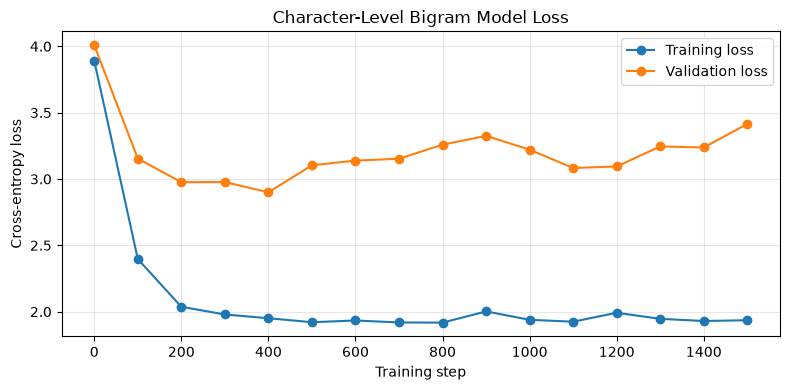

In [7]:
steps = [x["step"] for x in history]
plt.figure(figsize=(8, 4))
plt.plot(steps, [x["training_loss"] for x in history], marker="o", label="Training loss")
plt.plot(steps, [x["validation_loss"] for x in history], marker="o", label="Validation loss")
plt.xlabel("Training step")
plt.ylabel("Cross-entropy loss")
plt.title("Character-Level Bigram Model Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Save the trained model checkpoint

In [8]:
model_dir = project_dir / "model"
model_dir.mkdir(parents=True, exist_ok=True)
checkpoint_path = model_dir / "character_bigram_model.pt"
torch.save({"model_state_dict": model.state_dict(), "chars": chars, "stoi": stoi,
            "itos": itos, "vocab_size": vocab_size, "model_type": "character-level-bigram"},
           checkpoint_path)
print("Model saved:", checkpoint_path.resolve())

Model saved: C:\Users\YASH D JAIN\OneDrive\Desktop\skill-nexis-llm-development-week-2\SkillNexus_LLM_Development_Week_2\Mini_Project_2_Character_Level_Text_Generator\model\character_bigram_model.pt


## 7. Generate ten samples from a starter sequence
Change `STARTER_SEQUENCE` to a sequence found in the training vocabulary. Each output continues from the chosen starter.

In [9]:
STARTER_SEQUENCE = "Mira"
NUMBER_OF_SAMPLES = 10
NEW_CHARACTERS_PER_SAMPLE = 120
starter = torch.tensor([encode(STARTER_SEQUENCE)], dtype=torch.long)
samples = []
model.eval()
for i in range(NUMBER_OF_SAMPLES):
    ids = model.generate(starter.clone(), NEW_CHARACTERS_PER_SAMPLE)
    sample = decode(ids[0].tolist())
    samples.append(sample)
    print(f"Sample {i+1:02d}:\n{sample}\n")

samples_path = project_dir / "generated_samples.txt"
with samples_path.open("w", encoding="utf-8") as f:
    for i, sample in enumerate(samples, 1):
        f.write(f"Sample {i:02d}\n{sample}\n\n")
print("Generated samples saved:", samples_path.resolve())

Sample 01:
Miran wigalithtusise n ny flove ghd arnes tenee f apa ran foweettchtetwe hedeantthe flol sige shethe ghtsiglske alin. Theend

Sample 02:
Mira wine. sird ga arasen ske lile ganola shered sevearirne gary s shtheter ve s. siked. t, flSopa Mir a fle irantla Min. pa

Sample 03:
Mira g, senilouiniker the the quig, tlerird onthe tesed s. orilitonthed foweee gen ane siveeee panttry tt a seney gary flori

Sample 04:
Mirabon, toflir ape atld ire the athttolowive t ppard. Milir. thand Misen. owed lld s a told ld By raba fow foweded a a sed 

Sample 05:
Mirasttlind Mir a gry araneenend. ten t maleh moot a tasera toof te athe s. owanee att, t bone ise an irne s lo ar e a mofog

Sample 06:
Mirare houatlise foldeth ed atonglinedse sivedether a s. on, tontoll e ta towa s. pe thenthe id. fouridea ng, patien, Mie of

Sample 07:
Miraritwed thed wed arn che ire boween se Mikeny ile ieenikes. mowinghe the inthen fovethed weneves skentht. wed fox a fon. 

Sample 08:
Miralistherd ant a fl. ligabol

## 8. Compare the measured results and conclude

In [10]:
first, last = history[0], history[-1]
print("Initial training loss:", round(first["training_loss"], 4))
print("Final training loss:", round(last["training_loss"], 4))
print("Initial validation loss:", round(first["validation_loss"], 4))
print("Final validation loss:", round(last["validation_loss"], 4))
print("Training loss decreased:", last["training_loss"] < first["training_loss"])
print("Validation loss decreased:", last["validation_loss"] < first["validation_loss"])
print("Number of generated samples:", len(samples))
print("\nInterpretation: describe the actual losses and samples from this run. A bigram model only conditions on the immediately preceding character, so output can be incoherent.")

Initial training loss: 3.8905
Final training loss: 1.9356
Initial validation loss: 4.0084
Final validation loss: 3.4152
Training loss decreased: True
Validation loss decreased: True
Number of generated samples: 10

Interpretation: describe the actual losses and samples from this run. A bigram model only conditions on the immediately preceding character, so output can be incoherent.


## Conclusion
The notebook trains a character-level bigram model, records training and validation loss, saves the model, and generates ten text continuations from a starter sequence.

**Limitation:** this is a small teaching model. It learns local character transitions, not meaning or long-range grammar.